# Deterministic Grid Solver for Self-Consistent Priors

This notebook solves the self-consistency equation on the two-dimensional zero-mean log-belief plane. It uses fixed Gaussian quadrature, bilinear grid transitions, and a nonuniform grid that is fine near the origin and wide in the tails.

For marginal prior $p$, let $G(p)=\frac13\sum_s p_s$ be the distribution generated by the state-conditioned update process. The target is $G(p)=p$. The reported residual is $\lVert G(p)-p\rVert_1$ before damping.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from deterministic_grid_solver import (
    initialize_prior, make_grid, prepare_map, solve, summarize,
)

np.set_printoptions(precision=4, suppress=True)

## Parameters

In [2]:
STATES = ['Healthy', 'Sickness 1', 'Sickness 2']
SIGNALS = ['Whistle', 'Cough', 'Scratch']

# Rows are signals; columns are states.
L = np.array([
    [0.70, 0.20, 0.20],
    [0.15, 0.60, 0.20],
    [0.15, 0.20, 0.60],
])

SIGMA = 0.15
AGE_LAMBDA = 0.90

# Fine center, coarser tails.
GRID_LIMIT = 40.0
GRID_STEP = 0.15
GRID_GROWTH = 1.06

QUADRATURE_ORDER = 3
GAUSSIAN_CUTOFF_SIGMA = 6.0
DAMPING = 1.0
FLOOR_MASS = 1e-8
MAX_ITERATIONS = 50
TOLERANCE = 1e-5

## Geometry and deterministic map

In [3]:
b1 = np.array([1.0, -1.0, 0.0]) / np.sqrt(2)
b2 = np.array([1.0, 1.0, -2.0]) / np.sqrt(6)
B = np.column_stack([b1, b2])
z_delta = np.array([B.T @ (np.log(row) - np.log(row).mean()) for row in L])

grid = make_grid(GRID_LIMIT, GRID_STEP, GRID_GROWTH)
prepared = prepare_map(
    grid, z_delta, SIGMA, QUADRATURE_ORDER, GAUSSIAN_CUTOFF_SIGMA,
)

print('B.T @ B =')
print(B.T @ B)
print(f'grid: {grid["n"]} x {grid["n"]} = {len(grid["points"])} points')
print('projected signal displacements:')
for signal, displacement in zip(SIGNALS, z_delta):
    print(f'{signal:>10}: {displacement}')

B.T @ B =
[[1. 0.]
 [0. 1.]]
grid: 99 x 99 = 9801 points
projected signal displacements:
   Whistle: [0.8858 0.5114]
     Cough: [-0.9803  0.3311]
   Scratch: [-0.2034 -1.0145]


## Solve

In [4]:
initial_weights = initialize_prior(grid, kind='wide_gaussian', scale=2.0)
weights, conditioned, history = solve(
    initial_weights, grid, prepared, L,
    lam=AGE_LAMBDA,
    damping=DAMPING,
    floor_mass=FLOOR_MASS,
    max_iterations=MAX_ITERATIONS,
    tolerance=TOLERANCE,
)

result = summarize(weights, grid)
print(f'final raw residual: {history[-1]["raw_residual"]:.6g}')
print(f'boundary mass: {result["boundary_mass"]:.6g}')
print(f'covariance trace: {result["trace"]:.6f}')
print('marginal mean:', result['mean'])
print('marginal covariance:')
print(result['covariance'])
print('state-conditioned means:')
print(conditioned @ grid['points'])

iter 001 | residual=0.906366 | trace=7.9955 | boundary=3.75e-10


iter 010 | residual=0.0209363 | trace=51.8440 | boundary=0.000191


iter 020 | residual=0.00266373 | trace=51.8508 | boundary=0.000191


iter 030 | residual=0.000291789 | trace=51.8473 | boundary=0.000191


iter 040 | residual=3.3071e-05 | trace=51.8472 | boundary=0.000191


iter 046 | residual=9.04495e-06 | trace=51.8472 | boundary=0.000191
final raw residual: 9.05168e-06
boundary mass: 0.000191484
covariance trace: 51.847211
marginal mean: [-0.4725 -0.2879]
marginal covariance:
[[30.8125  9.1143]
 [ 9.1143 21.0347]]
state-conditioned means:
[[ 4.4285  2.5479]
 [-4.4413  0.9701]
 [-1.4049 -4.3818]]


## Convergence checks

- Domain radius 32: residual `9.02e-6`, boundary mass `2.12e-3`, trace `51.48`.
- Domain radius 40: residual `9.04e-6`, boundary mass `1.91e-4`, trace `51.85`.
- Center spacings from `0.20` to `0.30` changed the trace by less than `0.3%` in the resolution test.
- Quadrature orders 3 and 5 changed the trace by about `0.2%` in the quadrature test.
- Wide, narrow, three-bump, and uniform initial priors converged to the same diffuse branch.
- Independent simulation with 20,000 trajectories per state gave marginal trace `52.49`, within `1.3%` of the grid value.

The exact point mass at the origin remains a separate trivial fixed point.

## Diagnostics

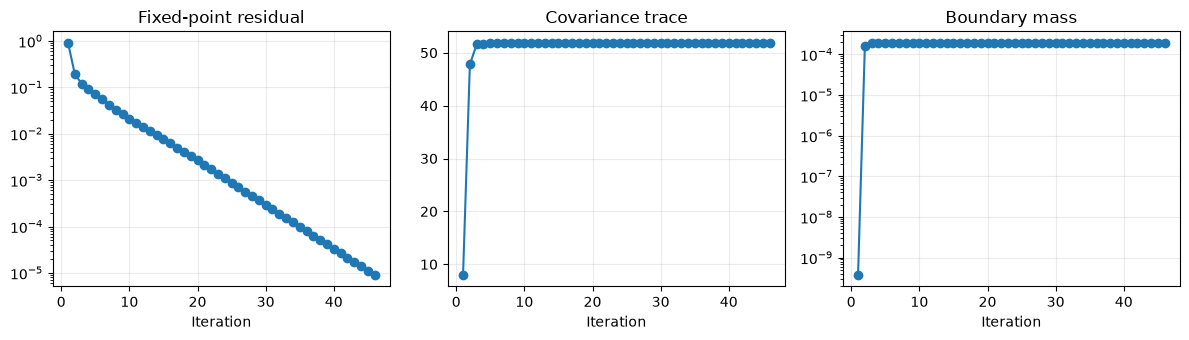

In [29]:
iterations = np.array([row['iteration'] for row in history])
residual = np.array([row['raw_residual'] for row in history])
trace = np.array([row['trace'] for row in history])
boundary = np.array([row['boundary_mass'] for row in history])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].semilogy(iterations, residual, marker='o')
axes[0].set_title('Fixed-point residual')
axes[1].plot(iterations, trace, marker='o')
axes[1].set_title('Covariance trace')
axes[2].semilogy(iterations, boundary, marker='o')
axes[2].set_title('Boundary mass')
for ax in axes:
    ax.set_xlabel('Iteration')
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Inspecting the marginal prior

`mass_2d[j, i]` is the probability mass at $(z_1[i], z_2[j])`; it is `weights` reshaped onto the grid. Because the grid is nonuniform, use `density_2d = mass_2d / area_2d` for density plots. The figures show the exact log-space density, horizontal and vertical density slices, and a coarse mass-preserving simplex histogram. There is no display sampling or smoothing.

mass_2d shape: (99, 99)
total mass: 1.0000000000000002
rows are z2; columns are z1


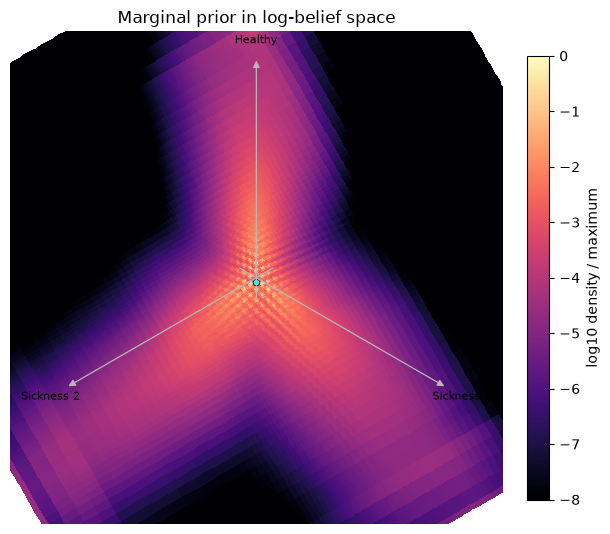

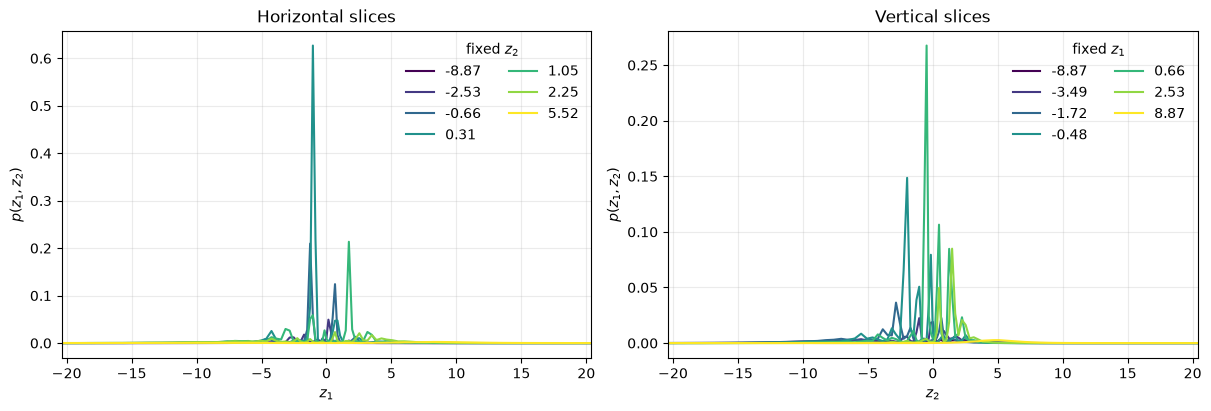

simplex histogram mass: 0.9999993986736859


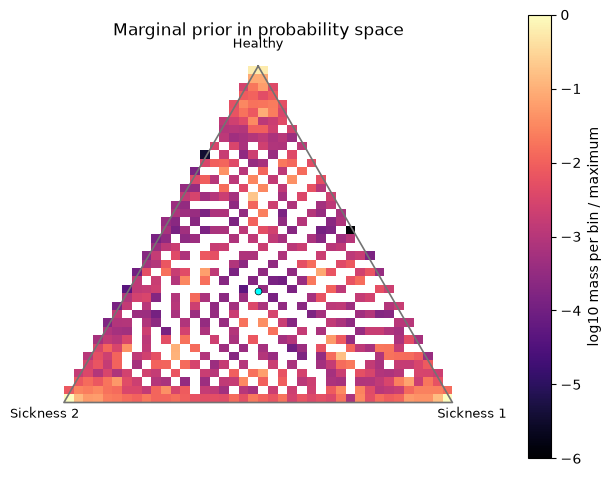

In [30]:
z = grid['xs']
mass_2d = weights.reshape(grid['n'], grid['n'])
area_2d = grid['area'].reshape(grid['n'], grid['n'])
density_2d = mass_2d / area_2d
print('mass_2d shape:', mass_2d.shape)
print('total mass:', mass_2d.sum())
print('rows are z2; columns are z1')

display_frame = np.array([
    [0.0, 1.0],
    [np.sqrt(3) / 2, -0.5],
    [-np.sqrt(3) / 2, -0.5],
])
edge_z1, edge_z2 = np.meshgrid(grid['edges'], grid['edges'], indexing='xy')
edge_z = np.stack([edge_z1, edge_z2], axis=-1)
edge_xy = edge_z @ B.T @ display_frame
grid_xy = grid['points'] @ B.T @ display_frame
order = np.argsort(np.linalg.norm(grid_xy, axis=1))
radius = 1.15 * np.linalg.norm(grid_xy, axis=1)[order][np.searchsorted(np.cumsum(weights[order]), 0.99)]
log_density = np.log10(np.maximum(density_2d / density_2d.max(), 1e-8))

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
image = ax.pcolormesh(edge_xy[..., 0], edge_xy[..., 1], log_density,
                      shading='flat', cmap='magma', vmin=-8, vmax=0)
for state, direction in zip(STATES, display_frame):
    ax.annotate('', xy=radius * direction, xytext=-0.1 * radius * direction,
                arrowprops=dict(arrowstyle='-|>', color='0.72', lw=0.9))
    ax.text(*(1.08 * radius * direction), state, ha='center', va='center', fontsize=8)
ax.scatter(*(weights @ grid_xy), s=22, color='cyan', edgecolor='black', linewidth=0.5)
ax.set_title('Marginal prior in log-belief space')
ax.set(xlim=(-1.12 * radius, 1.12 * radius), ylim=(-1.12 * radius, 1.12 * radius))
ax.set_aspect('equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.75, label='log10 density / maximum')
plt.show()

def quantile_indices(mass, quantiles):
    """Return grid indices at weighted quantiles."""
    return np.unique(np.searchsorted(np.cumsum(mass), quantiles))

mass_z1 = mass_2d.sum(axis=0)
mass_z2 = mass_2d.sum(axis=1)
quantiles = np.linspace(0.05, 0.95, 7)
z1_slices = quantile_indices(mass_z1, quantiles)
z2_slices = quantile_indices(mass_z2, quantiles)
z1_limit = np.max(np.abs(z[quantile_indices(mass_z1, [0.005, 0.995])]))
z2_limit = np.max(np.abs(z[quantile_indices(mass_z2, [0.005, 0.995])]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(quantiles)))
for index, color in zip(z2_slices, colors):
    axes[0].plot(z, density_2d[index], color=color, label=f'{z[index]:.2f}')
for index, color in zip(z1_slices, colors):
    axes[1].plot(z, density_2d[:, index], color=color, label=f'{z[index]:.2f}')
axes[0].set(title='Horizontal slices', xlabel='$z_1$', ylabel='$p(z_1,z_2)$', xlim=(-z1_limit, z1_limit))
axes[1].set(title='Vertical slices', xlabel='$z_2$', ylabel='$p(z_1,z_2)$', xlim=(-z2_limit, z2_limit))
axes[0].legend(title='fixed $z_2$', frameon=False, ncol=2)
axes[1].legend(title='fixed $z_1$', frameon=False, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

log_beliefs = grid['points'] @ B.T
probabilities = np.exp(log_beliefs - log_beliefs.max(axis=1, keepdims=True))
probabilities /= probabilities.sum(axis=1, keepdims=True)
simplex_xy = probabilities @ display_frame

simplex_bins = 40
x_edges = np.linspace(-np.sqrt(3) / 2, np.sqrt(3) / 2, simplex_bins + 1)
y_edges = np.linspace(-0.5, 1.0, simplex_bins + 1)
simplex_mass, _, _ = np.histogram2d(
    simplex_xy[:, 0], simplex_xy[:, 1],
    bins=[x_edges, y_edges], weights=weights,
)
print('simplex histogram mass:', simplex_mass.sum())
relative = simplex_mass.T / simplex_mass.max()
color = np.ma.masked_where(simplex_mass.T == 0, np.log10(np.maximum(relative, 1e-6)))

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
image = ax.pcolormesh(x_edges, y_edges, color, shading='flat', cmap='magma', vmin=-6, vmax=0)
closed = np.vstack([display_frame, display_frame[0]])
ax.plot(closed[:, 0], closed[:, 1], color='0.45', lw=1.2)
for state, vertex in zip(STATES, display_frame):
    ax.text(*(1.10 * vertex), state, ha='center', va='center', fontsize=9)
ax.scatter(*(weights @ simplex_xy), s=24, color='cyan', edgecolor='black', linewidth=0.5)
ax.set_title('Marginal prior in probability space')
ax.set_xlim(-1.02, 1.02)
ax.set_ylim(-0.62, 1.10)
ax.set_aspect('equal')
ax.axis('off')
fig.colorbar(image, ax=ax, shrink=0.75, label='log10 mass per bin / maximum')
plt.show()


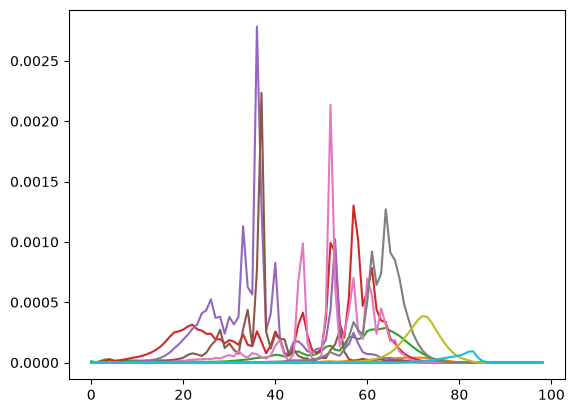

In [27]:
plt.plot( mass_2d[:,::10] );